In [15]:
!pip install yfinance

import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

In [16]:
tickers = ["AAPL", "MSFT", "NVDA"]

prices = yf.download(tickers=tickers, start="2023-11-01", end="2026-11-01")["Close"]

rets = np.log(prices / prices.shift(1)).dropna()

rets

/var/folders/x9/60hcc2ln62d3r3xyv90d3wl40000gn/T/ipykernel_55091/1569977385.py:3: FutureWarning: YF.download() has changed argument auto_adjust default to True
  prices = yf.download(tickers=tickers, start="2023-11-01", end="2026-11-01")["Close"]
[*********************100%***********************]  3 of 3 completed


Ticker,AAPL,MSFT,NVDA
Date,,,
2023-11-02,0.020482,0.006481,0.027521
2023-11-03,-0.005195,0.012780,0.033875
2023-11-06,0.014500,0.010517,0.016440
2023-11-07,0.014347,0.011157,0.004449
2023-11-08,0.005867,0.007379,0.013380
...,...,...,...
2026-10-26,-0.011046,0.015306,0.023610
2026-10-27,0.009233,-0.002387,0.008941
2026-10-28,-0.009466,-0.000602,-0.011816


In [17]:
rets.corr()

Ticker,AAPL,MSFT,NVDA
Ticker,,,
AAPL,1.000000,0.334250,0.284358
MSFT,0.334250,1.000000,0.421861
NVDA,0.284358,0.421861,1.000000


In [18]:
#Calcular matriz cov
Sigma = rets.cov()

Sigma

Ticker,AAPL,MSFT,NVDA
Ticker,,,
AAPL,0.000282,0.000092,0.000140
MSFT,0.000092,0.000267,0.000202
NVDA,0.000140,0.000202,0.000860


In [19]:
#descomponemos
L = np.linalg.cholesky(Sigma)

L

array([[0.01680768, 0.        , 0.        ],
       [0.00545684, 0.01538663, 0.        ],
       [0.00834016, 0.01017032, 0.02621528]])

In [20]:
#calculamos rendimientos promedio
mu = rets.mean().values * 252

mu

array([0.23388793, 0.14563172, 0.5297894 ])

In [21]:
#simulamos epsilon
M = 10000

epsilon = np.random.normal(0, 1, (3,M))

epsilon

array([[-0.39322184,  0.11340167, -0.96522496, ...,  1.81322982,
         0.20741181, -0.62615211],
       [-1.54718922,  0.56929553,  1.14352675, ..., -0.11629505,
        -0.40043805,  0.64014069],
       [ 0.48053821,  0.69828503,  1.68821933, ..., -0.911957  ,
         1.97256153,  0.37175584]])

In [22]:
#Transformamos epsilon 
Z = 0 + L @ epsilon 

Z.T

array([[-0.00660915, -0.02595179, -0.00641751],
       [ 0.00190602,  0.00937836,  0.02504144],
       [-0.0162232 ,  0.01232795,  0.04783704],
       ...,
       [ 0.03047619,  0.00810512, -0.00996733],
       [ 0.00348611, -0.00502958,  0.04936851],
       [-0.01052417,  0.0064328 ,  0.01103391]])

In [23]:
# Tiempo de simulación: un año
T = 1
n_act = len(prices.columns)
ST = np.zeros(shape=(M, n_act))
cont = 0
for i in prices.columns:
    S0 = prices.iloc[-1][i]
    mu = rets[i].mean() * 252
    vol = rets[i].std() * np.sqrt(252)
    
    ST[:, cont] = S0 * np.exp((mu - 0.5 * (vol ** 2) * T + vol * np.sqrt(T) * Z[cont, :]))
    cont += 1

ST

array([[419.47382604, 579.8786725 , 310.95997735],
       [420.42793874, 585.2125384 , 315.54817275],
       [418.39918758, 585.66005679, 318.91508707],
       ...,
       [423.64507127, 585.01946598, 310.44645305],
       [420.6052245 , 583.03144295, 319.14256967],
       [419.03588061, 584.76597234, 313.4969128 ]])

In [24]:
# Corregir precios futuros simulados
T = 1

S0 = prices.iloc[-1].values
mu = rets.mean().values * 252
vol = rets.std().values * np.sqrt(252)

ST = S0 * np.exp(
    (mu - 0.5 * vol**2) * T
    + np.sqrt(252 * T) * Z.T
)

ST

array([[378.36054439, 386.67044337, 281.68161994],
       [433.12296142, 677.50802737, 464.13375208],
       [324.80639215, 709.98558756, 666.50099075],
       ...,
       [681.67916963, 663.95171399, 266.24734426],
       [444.12446881, 538.9929443 , 682.90312871],
       [355.56162184, 646.55745672, 371.59703683]])

In [25]:

V0 = 100000
w = np.array([1/3, 1/3, 1/3])
acciones = (V0 * w) / S0
VT = ST @ acciones
PnL = VT - V0

PnL

array([ 7174.1435221 , 60765.28971945, 85326.08972038, ...,
       51707.09412094, 88617.5352694 , 36213.55456721])

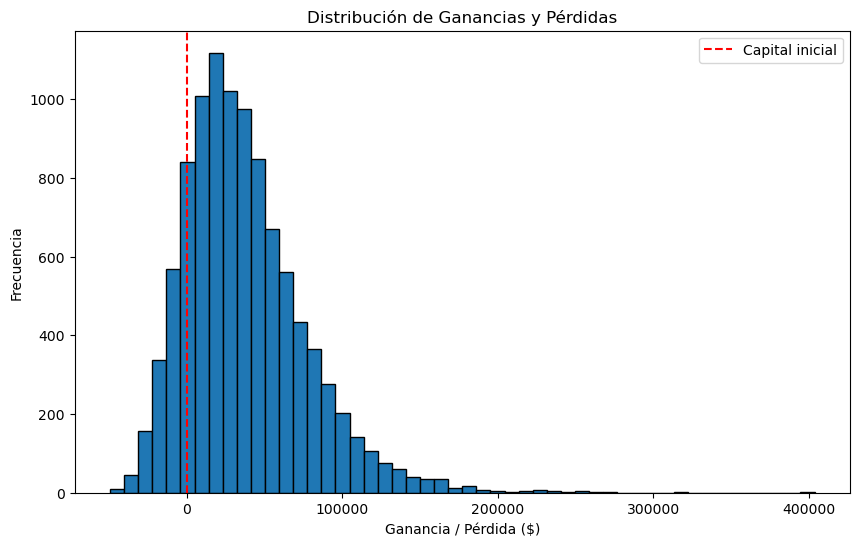

In [26]:
plt.figure(figsize=(10, 6))

plt.hist(PnL, bins=50, edgecolor="black")

plt.axvline(0, color="red", linestyle="--", label="Capital inicial")

plt.title("Distribución de Ganancias y Pérdidas")
plt.xlabel("Ganancia / Pérdida ($)")
plt.ylabel("Frecuencia")

plt.legend()
plt.show()